In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data() # Carga del conjunto de datos MNIST

In [2]:
x_train.shape[0]

60000

In [3]:
x_test.shape[0]

10000

In [4]:
gray_scale = 255

x_train = x_train.astype('float32') / gray_scale
x_test = x_test.astype('float32') / gray_scale

print("Feature matrix (x_train):", x_train.shape)
print("Target matrix (y_train):", y_train.shape)
print("Feature matrix (x_test):", x_test.shape)
print("Target matrix (y_test):", y_test.shape)

Feature matrix (x_train): (60000, 28, 28)
Target matrix (y_train): (60000,)
Feature matrix (x_test): (10000, 28, 28)
Target matrix (y_test): (10000,)


In [5]:
x_train[0][15]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.1764706 ,
       0.7294118 , 0.99215686, 0.99215686, 0.5882353 , 0.10588235,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        ], dtype=float32)

In [6]:
y_train[0:10]

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4], dtype=uint8)

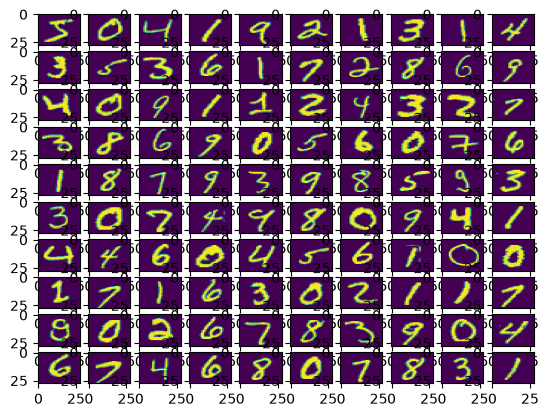

In [7]:
fig, ax = plt.subplots(10, 10)
k = 0
for i in range(10):
    for j in range(10):
        ax[i][j].imshow(x_train[k].reshape(28, 28), aspect='auto')
        k += 1
plt.show() # Uso del plote para visualizar las primeras 100 imágenes del conjunto de entrenamiento

In [8]:
model = Sequential([
    Flatten(input_shape=(28, 28)),     # Convierte la imagen 2D en una sola lista de datos plana
    Dense(256, activation='sigmoid'),  # Primera capa oculta con 256 neuronas para aprender los patrones principales
    Dense(128, activation='sigmoid'),  # Segunda capa oculta con 128 neuronas para refinar esos detalles
    Dense(10, activation='softmax'),   # Capa de salida que calcula la probabilidad de cada dígito (del 0 al 9)
])

c:\Users\jonat\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
model.compile(optimizer='adam', # Optimizer Adam para ajustar los pesos de la red neuronal
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
mod = model.fit(x_train, y_train, epochs=15, # Entrenamiento del modelo con 15 épocas
          batch_size=2000, 
          validation_split=0.2)
          
print(mod)

Epoch 1/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.4830 - loss: 2.0476 - val_accuracy: 0.7079 - val_loss: 1.6717
Epoch 2/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7351 - loss: 1.3260 - val_accuracy: 0.8154 - val_loss: 0.9770
Epoch 3/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8212 - loss: 0.8186 - val_accuracy: 0.8687 - val_loss: 0.6362
Epoch 4/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8670 - loss: 0.5760 - val_accuracy: 0.8909 - val_loss: 0.4736
Epoch 5/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8889 - loss: 0.4526 - val_accuracy: 0.9029 - val_loss: 0.3883
Epoch 6/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9006 - loss: 0.3836 - val_accuracy: 0.9099 - val_loss: 0.3392
Epoch 7/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9082 - loss: 0.3410 - val_accuracy: 0.9169 - val_loss: 0.3076
Epoch 8/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9141 - loss: 0.3117 - val_accuracy: 0.9215 - val_loss

In [11]:
results = model.evaluate(x_test, y_test, verbose=0) # Evaluación del modelo en el conjunto de prueba para obtener la pérdida y precisión
print('Test loss, Test accuracy:', results)

Test loss, Test accuracy: [0.20940329134464264, 0.9395999908447266]


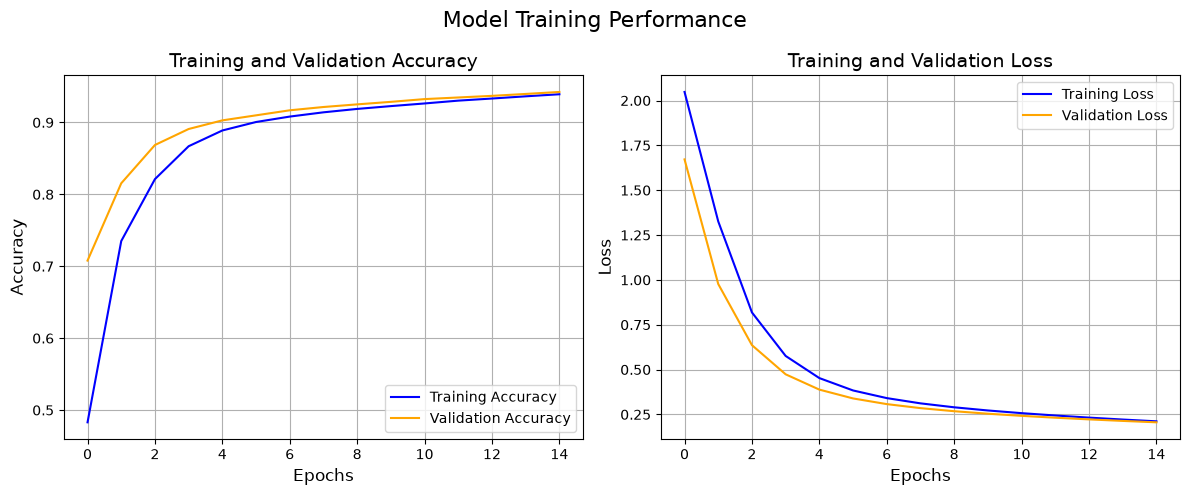

In [12]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(mod.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(mod.history['val_accuracy'],
         label='Validation Accuracy', color='orange')
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(mod.history['loss'], label='Training Loss', color='blue')
plt.plot(mod.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True)

plt.suptitle("Model Training Performance", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
model.save("mlp_model.keras") # Guardar el modelo entrenado en un archivo para su uso futuro